# Series de tiempo en futuros de oro (MGC)

Análisis del micro futuro de oro con datos diarios de Yahoo Finance:

1. Limpieza y estadísticas de retornos (volatilidad, asimetría, VaR, CVaR)
2. Forma de la distribución: normal vs t de Student
3. Estacionariedad y autocorrelación
4. ARIMA sobre el precio, con evaluación fuera de muestra
5. Volatilidad condicional: GARCH(1,1) y búsqueda entre GARCH, GJR-GARCH y EGARCH

Las funciones están en el paquete `seriesfin/`; aquí solo se llaman y se comentan los resultados.

In [1]:
import warnings

import numpy as np
import pandas as pd

from seriesfin import SEED, arima, datos, diagnostico, estadisticas, evaluacion, volatilidad
from seriesfin import graficos as g
from seriesfin.estilo import aplicar_estilo

# statsmodels avisa de cambios futuros en adfuller y acorr_lm; no afectan los resultados
warnings.filterwarnings('ignore', category=FutureWarning)

aplicar_estilo()
np.random.seed(SEED)
pd.set_option('display.float_format', '{:,.4f}'.format)

## Parámetros

Todo lo que se cambia seguido está aquí. `CORTE` separa entrenamiento y prueba: el test va desde esa fecha hasta el último dato disponible.

In [2]:
# Parte 1: retornos y riesgo de un contrato
TICKER = 'MGC=F'
INICIO_RIESGO = '2021-01-01'

# Parte 2: series de tiempo
PRINCIPAL = 'MGC=F'                # serie para ARIMA y GARCH
SISTEMA = ['MGC=F']                # series que se cargan en las secciones 3 a 5
INICIO = '2021-01-01'
FIN = None                         # None = hasta hoy
CORTE = '2026-09-28'
H_FUT = 10                         # días hábiles a proyectar después del último dato
HORIZONTE_VOL = 10
GARCH_SOLO_TRAIN = False           # True = GARCH se ajusta solo con datos de entrenamiento

## 1. Datos y limpieza

Yahoo entrega el futuro continuo (`MGC=F`) **sin ajustar por roll**: en cada vencimiento aparece un salto en el precio que entra como si fuera un retorno. La limpieza marca esos retornos atípicos con un z-score robusto (MAD) pero no los borra, para que se vea cuánto pesan. Si se quiere una serie sin rolls, se puede usar un ETF como GLD o IAU (multiplicador 1).

In [3]:
crudo = datos.descargar(TICKER, INICIO_RIESGO)
df, reporte = datos.limpiar(crudo)
df = df.dropna(subset=['log_ret'])
r = df['log_ret']

pd.Series(reporte, name=TICKER).to_frame()

,MGC=F
filas_originales,1466
duplicados,0
nulos,0
filas_descartadas,0
outliers_marcados,4
filas_finales,1466
desde,2021-01-04
hasta,2026-10-29


## 2. Retornos y riesgo

El VaR y el CVaR se pasan a dólares por contrato con el multiplicador del futuro (10 onzas en el micro oro).

Volatilidad anual con outliers: 18.55% | sin outliers: 17.35%


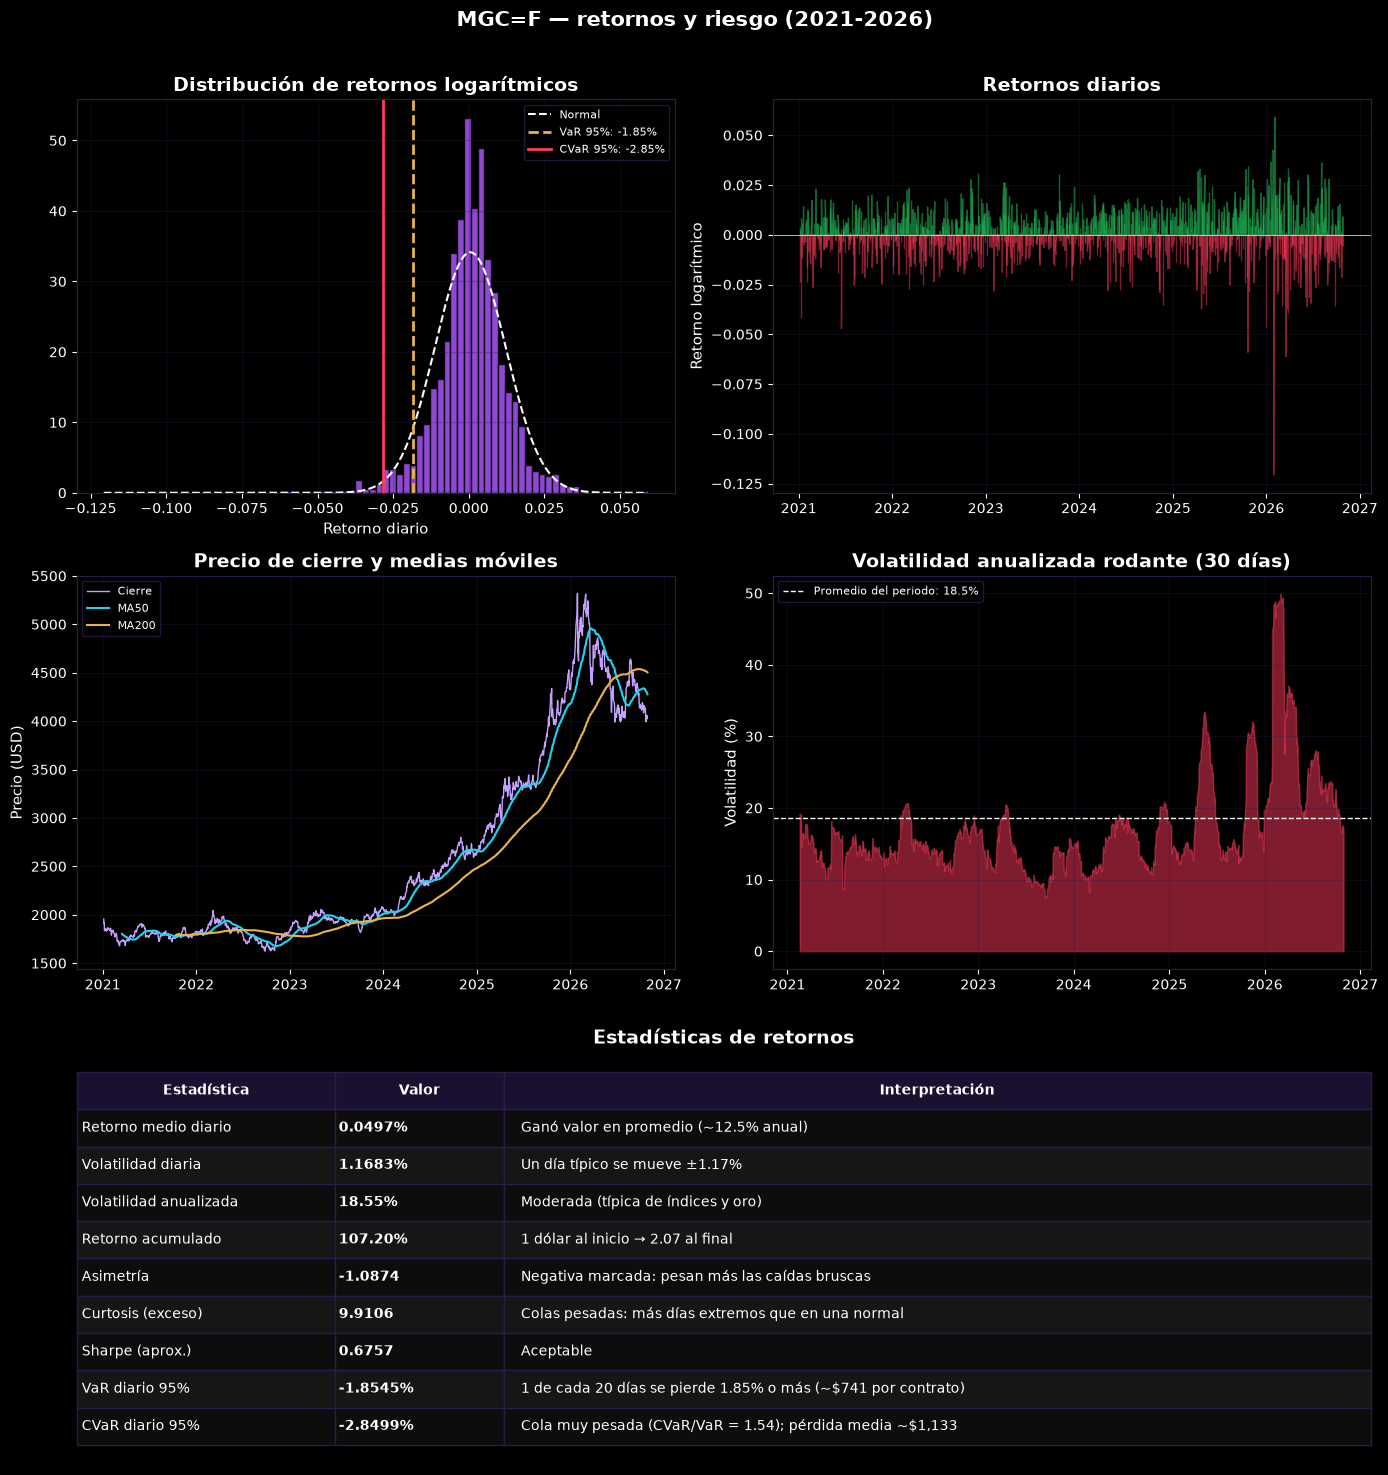

In [4]:
s = estadisticas.calcular_stats(r)
multiplicador = datos.MULTIPLICADORES.get(TICKER, 1)
filas = estadisticas.tabla_resumen(s, df['Close'].iloc[-1], multiplicador)

s_sin = estadisticas.calcular_stats(r[~df['outlier_ret']])
print(f"Volatilidad anual con outliers: {s['vol_a']:.2%} | sin outliers: {s_sin['vol_a']:.2%}")

g.dashboard(df, r, s, filas, TICKER, guardar='01_dashboard')

### Forma de la distribución

Si los retornos tienen colas más pesadas que la normal, un VaR calculado con la normal se queda corto. Se compara contra una t de Student ajustada por máxima verosimilitud.

Jarque-Bera:  6,237.86 (p = 0)
Shapiro-Wilk: 0.9327 (p = 3.6e-25)
Se rechaza normalidad: con la normal se subestima el riesgo de cola.

t de Student: 3.63 grados de libertad (colas muy pesadas)
AIC normal: -8,876.9 | AIC t: -9,122.1 → mejor ajuste: t

Días a más de 3σ: 18 observados, 4.0 esperados con la normal, 21.8 con la t


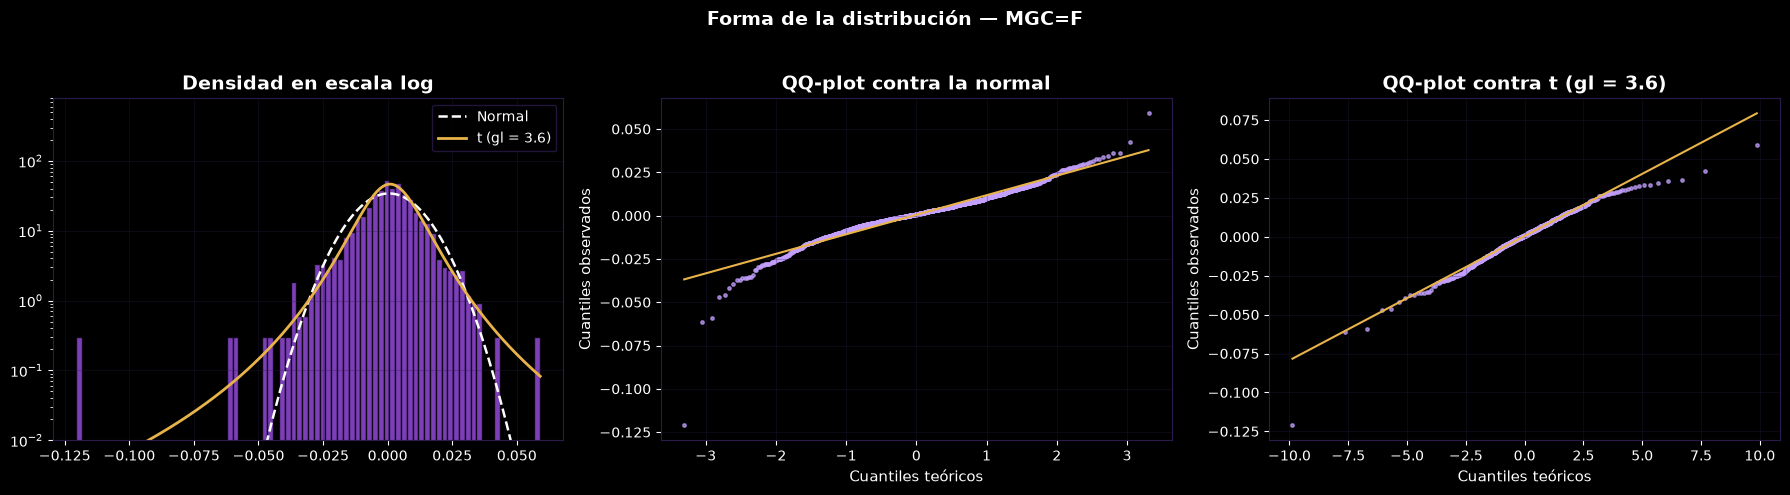

,Histórico,Normal,t de Student
Confianza,,,
95%,-1.8550,-1.8710,-1.6690
99%,-3.2530,-2.6670,-3.0910


In [5]:
ajuste = estadisticas.pruebas_normalidad(r)
estadisticas.reporte_normalidad(ajuste)
g.distribucion(r, ajuste, TICKER, guardar='02_distribucion')

# VaR diario en % según cada método
(ajuste['tabla_var'] * 100).round(3)

## 3. Series de tiempo de MGC

Desde aquí se trabaja con el precio y los retornos del contrato principal. Los retornos van en % porque GARCH converge mejor en esa escala.

In [6]:
precios, ohlc, retornos = datos.cargar_sistema(SISTEMA, PRINCIPAL, INICIO, FIN)
serie = precios[PRINCIPAL]
ret = retornos[PRINCIPAL]

print(f'{len(precios)} observaciones: {precios.index[0].date()} a {precios.index[-1].date()}')
datos.resumen_precios(precios, retornos)

1466 observaciones: 2021-01-04 a 2026-10-29


,Inicial,Final,Retorno (%),Vol. anual (%)
Ticker,,,,
MGC=F,"1,946.6000","4,033.3000",107.2000,18.5000


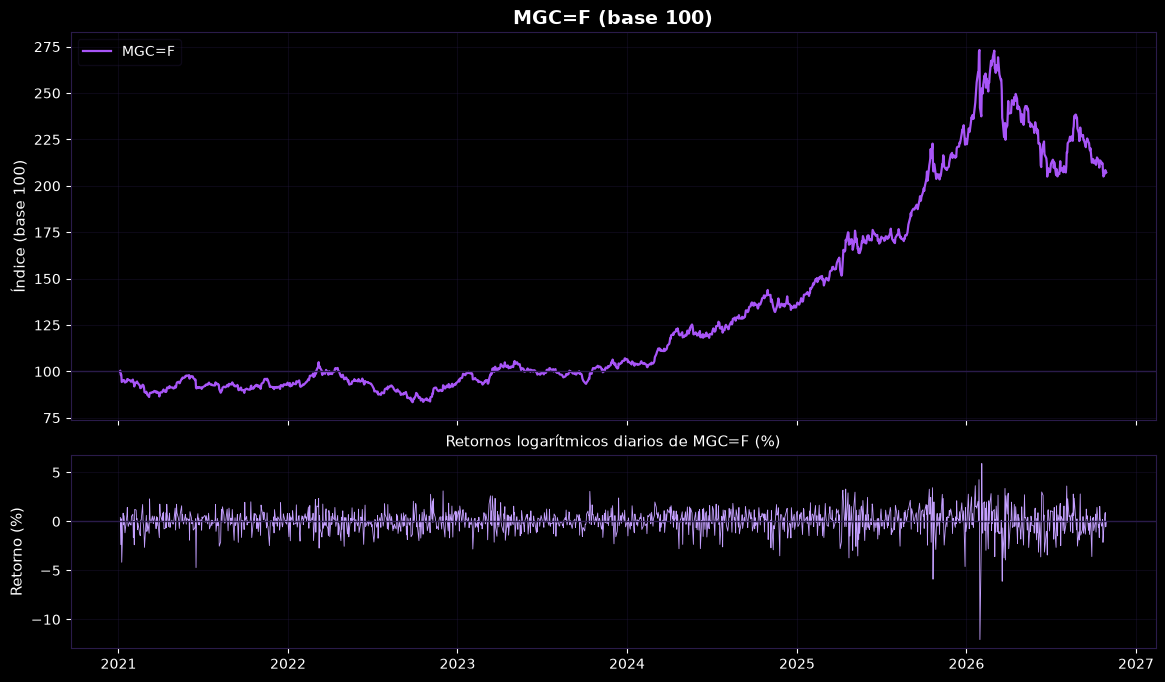

In [7]:
g.series(precios, ret, PRINCIPAL, guardar='03_series')

Los precios tienen tendencia; los retornos oscilan alrededor de cero, pero su amplitud no es constante. Esas rachas de días agitados (volatility clustering) son lo que modela GARCH más abajo.

### Estacionariedad

ADF y KPSS tienen hipótesis nulas opuestas, así que se usan juntas: una serie es estacionaria si ADF rechaza y KPSS no.

In [8]:
diagnostico.tabla_estacionariedad(serie, ret, PRINCIPAL)

,ADF p,KPSS p,Veredicto
Serie,,,
MGC=F precio,0.9538,0.0100,No estacionaria
MGC=F Δ precio,0.0000,0.1000,Estacionaria
MGC=F retorno log,0.0000,0.1000,Estacionaria
MGC=F retorno²,0.0000,0.0100,Ambigua


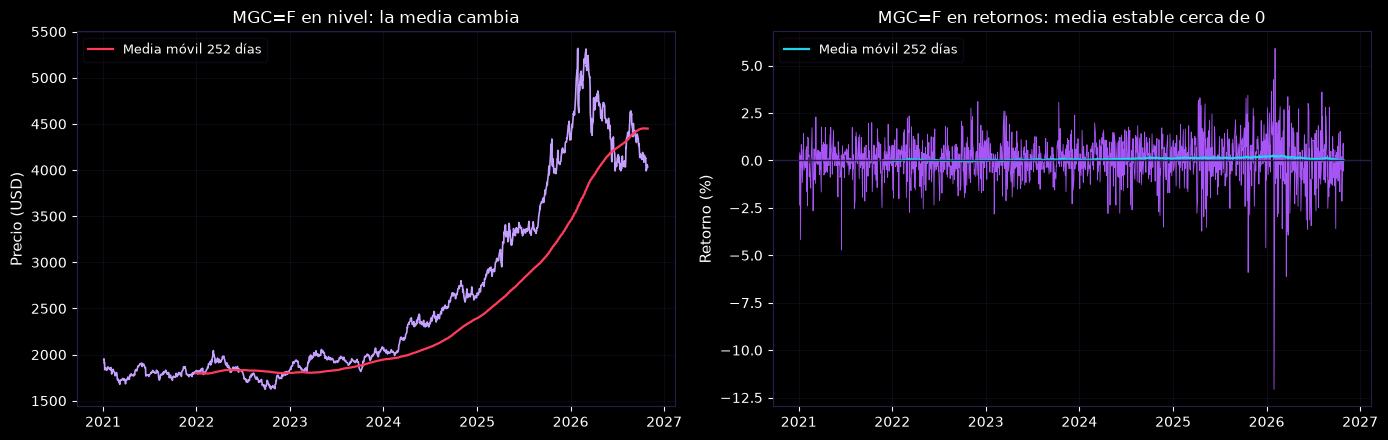

In [9]:
g.nivel_vs_retornos(serie, ret, PRINCIPAL)

El precio en nivel no es estacionario, por eso el ARIMA usa d = 1. Los retornos sí lo son, y sobre ellos trabaja GARCH.

### Autocorrelación

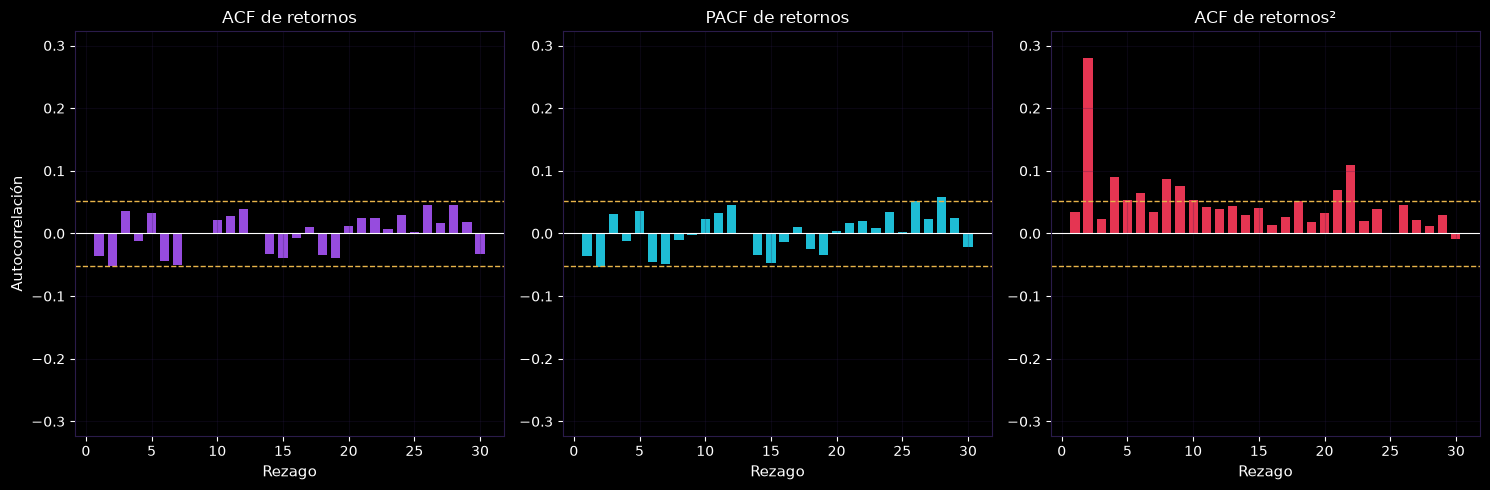

Rezagos significativos (de 30): retornos 1, retornos² 9


In [10]:
ac = diagnostico.autocorrelaciones(ret, nlags=30)
g.autocorrelaciones(ac, guardar='04_acf')

sig = diagnostico.rezagos_significativos(ac)
print(f"Rezagos significativos (de 30): retornos {sig['retornos']}, retornos² {sig['retornos²']}")

La ACF de los retornos es casi plana: la dirección del día siguiente es difícil de anticipar. La de los retornos al cuadrado sí persiste, o sea que la *magnitud* de los movimientos tiene memoria.

## 4. ARIMA

El orden (p, 1, q) se elige por AIC en una rejilla de 0 a 3, usando solo el periodo de entrenamiento.

In [11]:
train, test = arima.dividir(serie, CORTE)
print(f'Train: {len(train)} obs. ({train.index[0].date()} a {train.index[-1].date()})')
print(f'Test:  {len(test)} obs. ({test.index[0].date()} a {test.index[-1].date()})')

tabla_aic, orden = arima.seleccionar_orden(train)
print(f'\nOrden elegido: ARIMA{orden}')
tabla_aic.head()

Train: 1442 obs. (2021-01-04 a 2026-09-25)
Test:  24 obs. (2026-09-28 a 2026-10-29)

Orden elegido: ARIMA(3, 1, 3)


,p,d,q,AIC,BIC
0,3,1,3,"14,779.1200","14,816.0400"
1,1,1,2,"14,786.0700","14,807.1600"
2,2,1,1,"14,786.1200","14,807.2100"
3,0,1,3,"14,787.2800","14,808.3700"
4,2,1,0,"14,787.5200","14,803.3400"


In [12]:
modelo_arima = arima.ajustar(train, orden)
resid = arima.residuos(modelo_arima, train, orden)

display(arima.coeficientes(modelo_arima))

# Ljung-Box, H0: los residuos son ruido blanco
arima.ljung_box(resid, orden).round(4)

,coef,p-valor
ar.L1,-0.0818,0.2503
ar.L2,0.0171,0.8053
ar.L3,-0.8742,0.0000
ma.L1,0.0195,0.7997
ma.L2,-0.0587,0.4358
ma.L3,0.8900,0.0000
sigma2,"1,636.0971",0.0000


,lb_stat,lb_pvalue
10,19.9492,0.0005
20,47.3522,0.0000


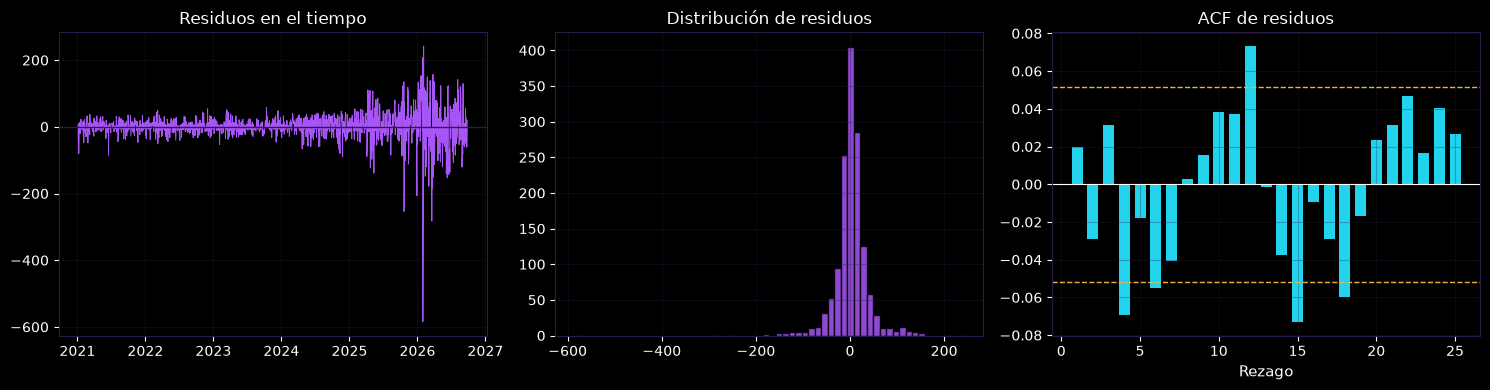

In [13]:
g.residuos_arima(resid)

### Pronóstico

Pronóstico dinámico sobre todo el test y `H_FUT` días hábiles más, con bandas al 80, 95 y 99%.

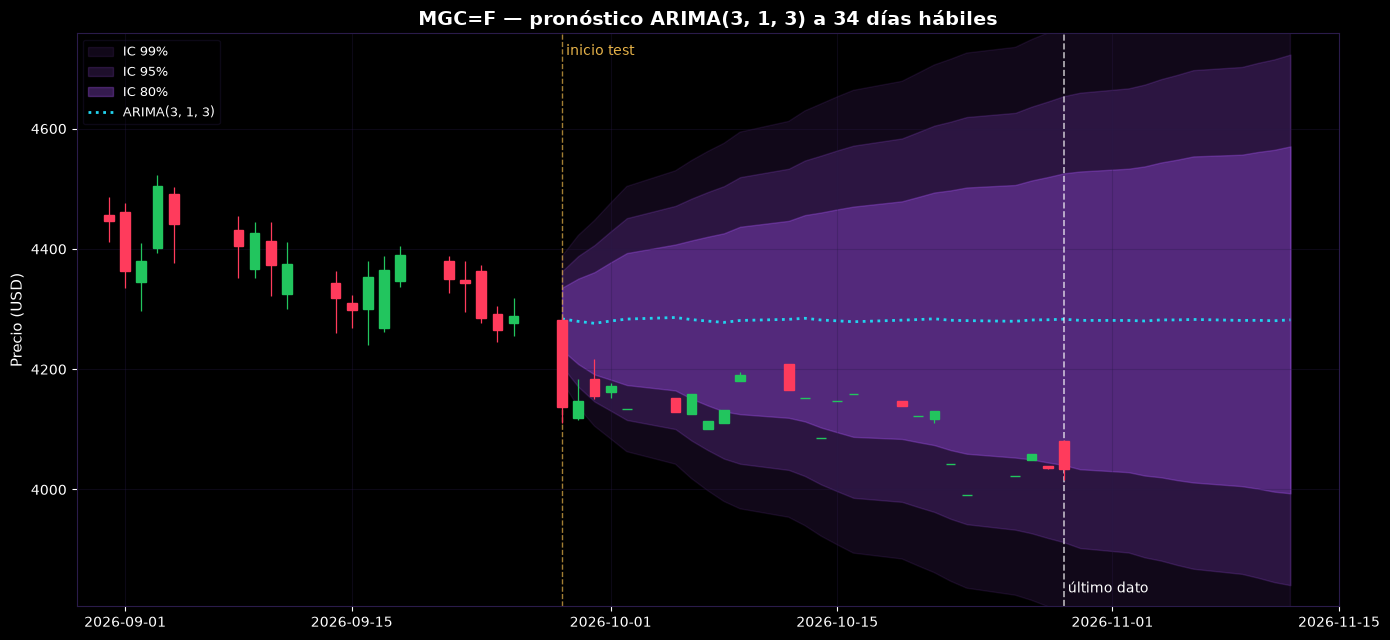

Ancho del IC 95%: $159 el primer día y $882 el día 34


In [14]:
pron = arima.pronosticar(modelo_arima, test, H_FUT)
g.pronostico_arima(ohlc, pron, CORTE, orden, PRINCIPAL, guardar='05_pronostico_arima')

ancho = pron['sup_95'] - pron['inf_95']
print(f'Ancho del IC 95%: ${ancho.iloc[0]:,.0f} el primer día y ${ancho.iloc[-1]:,.0f} el día {len(pron)}')

Un ARIMA(p,1,q) sin drift converge rápido al último precio conocido. A horizontes largos lo útil es el intervalo, no la línea central.

### Evaluación fuera de muestra

Cada pronóstico se compara con el benchmark que le corresponde: el de 1 paso contra el precio de ayer (paseo aleatorio) y el multi-paso contra el último precio del entrenamiento. La U de Theil es el cociente de RMSE: menor que 1 significa que el modelo le gana al ingenuo.

In [15]:
pred_1paso = evaluacion.pronostico_un_paso(modelo_arima, serie, train, test)
tabla_eval = evaluacion.evaluar(test, train, serie, pred_1paso, pron['media'], orden)
tabla_eval

,RMSE,MAE,MAPE (%),R²,U de Theil
Modelo,,,,,
"ARIMA(3, 1, 3) a 1 paso",47.2929,33.1091,0.8064,0.2238,0.9852
Ingenuo: precio de ayer,48.0051,35.1875,0.8564,0.2002,1.0000
"ARIMA(3, 1, 3) a 24 pasos",175.0774,166.5990,4.0666,-9.6382,0.9670
Ingenuo: último precio del train,181.0484,172.9081,4.2199,-10.3762,1.0000


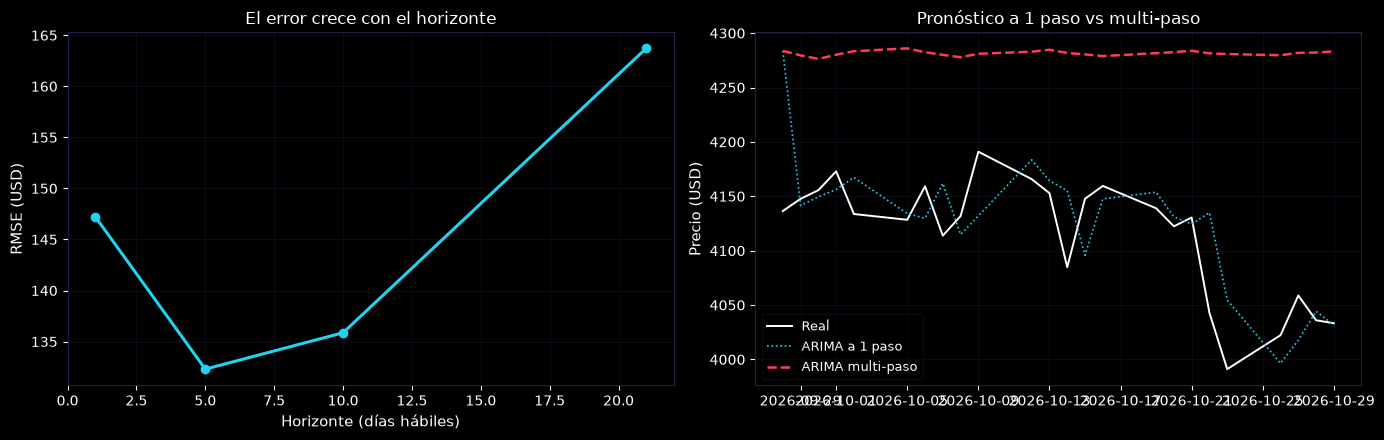

,RMSE,MAE,U de Theil
Horizonte,,,
1,147.2494,147.2494,0.9726
5,132.3022,131.3281,0.9500
10,135.8649,133.9731,0.9538
21,163.7170,156.1569,0.9637


In [16]:
tabla_h = evaluacion.error_por_horizonte(pron['media'], test, train)
g.error_horizonte(tabla_h, test, pred_1paso, pron['media'], guardar='06_error_horizonte')
tabla_h

El R² del pronóstico a 1 paso sale altísimo porque el precio de hoy se parece mucho al de ayer, no porque el modelo sepa algo. La U de Theil lo deja claro: si queda cerca de 1, el ARIMA no aporta nada frente al paseo aleatorio, que es lo esperable en un activo tan líquido.

## 5. Volatilidad

Primero se confirma que hay efecto ARCH; si lo hay, tiene sentido modelar la varianza condicional.

ARCH-LM: 131.95 (p = 1.9e-23)


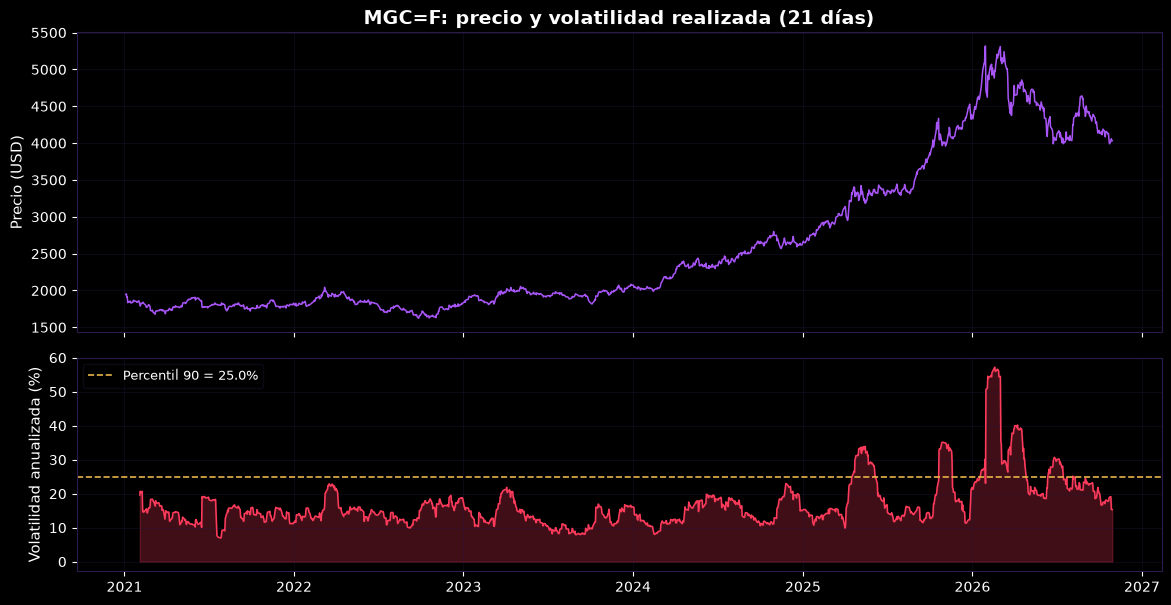

Días con volatilidad sobre el percentil 90: 145


In [17]:
lm, p_lm = diagnostico.prueba_arch(ret)
print(f'ARCH-LM: {lm:.2f} (p = {p_lm:.2g})')

dias_altos = g.clustering(serie, ret, PRINCIPAL, guardar='07_clustering')
print(f'Días con volatilidad sobre el percentil 90: {dias_altos}')

### GARCH(1,1) con t student

Se usa la t de Student por lo visto en la sección 2: las colas son más pesadas que las de una normal.

,valor
mu,0.0792
omega,0.0227
alpha[1],0.0432
beta[1],0.9398
nu,4.8541


Persistencia α + β: 0.9830 (vida media de un shock: 40.4 días)
Volatilidad actual: 18.1% | largo plazo: 18.4%


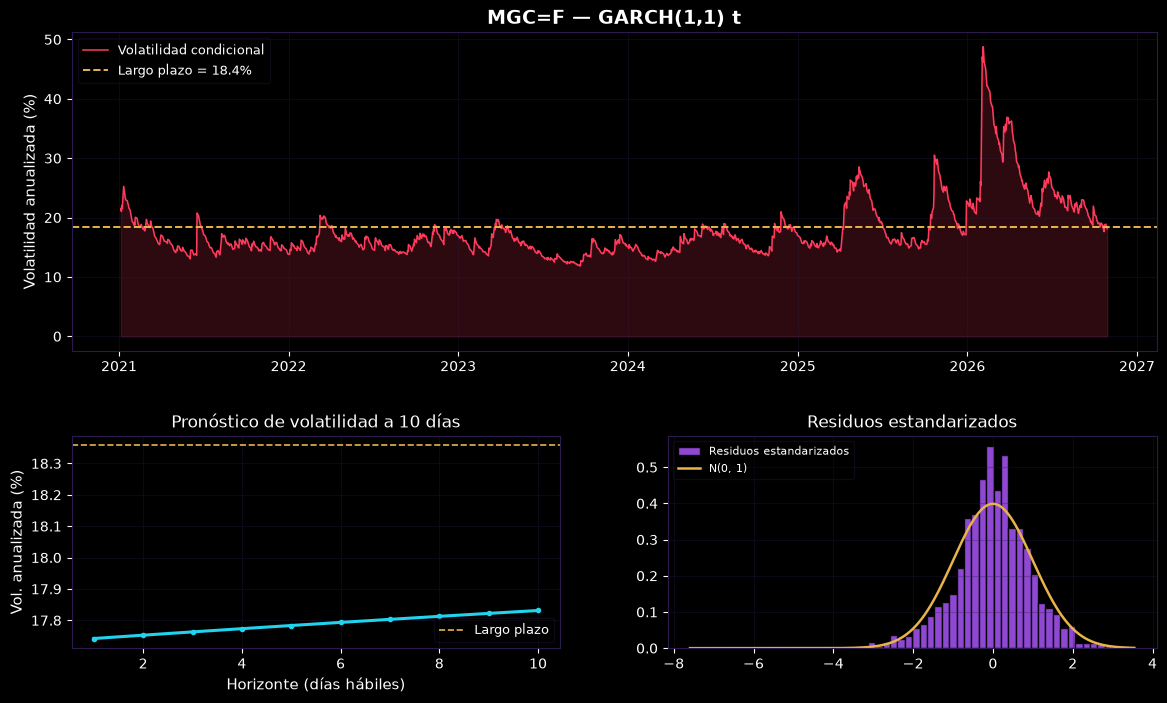

In [18]:
ret_garch = ret.loc[ret.index < pd.Timestamp(CORTE)] if GARCH_SOLO_TRAIN else ret

config_base = volatilidad.configuracion('Garch', p=1, o=0, q=1, dist='t')
garch_base = volatilidad.ajustar(ret_garch, config_base)
v_base = volatilidad.resumir(garch_base, config_base, HORIZONTE_VOL)

display(garch_base.params.round(5).to_frame('valor'))
print(f"Persistencia α + β: {v_base['persistencia']:.4f} "
      f"(vida media de un shock: {v_base['vida_media']:.1f} días)")
print(f"Volatilidad actual: {v_base['vol_cond'].iloc[-1]:.1f}% | largo plazo: {v_base['vol_lp']:.1f}%")

g.volatilidad(v_base, garch_base, PRINCIPAL)

### Búsqueda del modelo de volatilidad

GARCH, GJR-GARCH (asimetría con `o = 1`) y EGARCH, con órdenes 1 y 2 e innovaciones t o t asimétrica. Se descartan los ajustes que no convergen y se ordena por AIC.

In [19]:
tabla_vol, garch, config = volatilidad.buscar_modelo(ret_garch)
v = volatilidad.resumir(garch, config, HORIZONTE_VOL)

print(f"Mejor modelo por AIC: {config['nombre']}\n")
for linea in volatilidad.interpretar(v):
    print('-', linea)

tabla_vol.head(8)

Mejor modelo por AIC: EGARCH(2,1,1) t asimétrica

- Reacción a shocks (α = 0.1170): en EGARCH α actúa sobre log(σ²), no se compara directamente con el de un GARCH.
- Memoria (β = 0.9828): la volatilidad tarda en calmarse.
- Persistencia = 0.9828; un shock tarda 39.9 días hábiles en perder la mitad de su efecto.
- Asimetría (γ = 0.0433): las subidas suben la volatilidad más que las caídas; es común en el oro por su papel de refugio.
- Grados de libertad = 5.21: colas moderadas.


,AIC,BIC,Log-verosimilitud
Modelo,,,
"EGARCH(2,1,1) t asimétrica","4,256.0100","4,298.3300","-2,120.0100"
"EGARCH(1,1,1) t asimétrica","4,256.1600","4,293.1800","-2,121.0800"
"GJR-GARCH(1,1,1) t asimétrica","4,256.7800","4,293.8100","-2,121.3900"
"EGARCH(2,1,2) t asimétrica","4,256.9400","4,304.5500","-2,119.4700"
"GJR-GARCH(2,1,1) t asimétrica","4,257.5200","4,299.8400","-2,120.7600"
"EGARCH(1,1,2) t asimétrica","4,258.1600","4,300.4700","-2,121.0800"
"GJR-GARCH(1,1,2) t asimétrica","4,258.7800","4,301.1000","-2,121.3900"
"GJR-GARCH(2,1,2) t asimétrica","4,259.0200","4,306.6200","-2,120.5100"


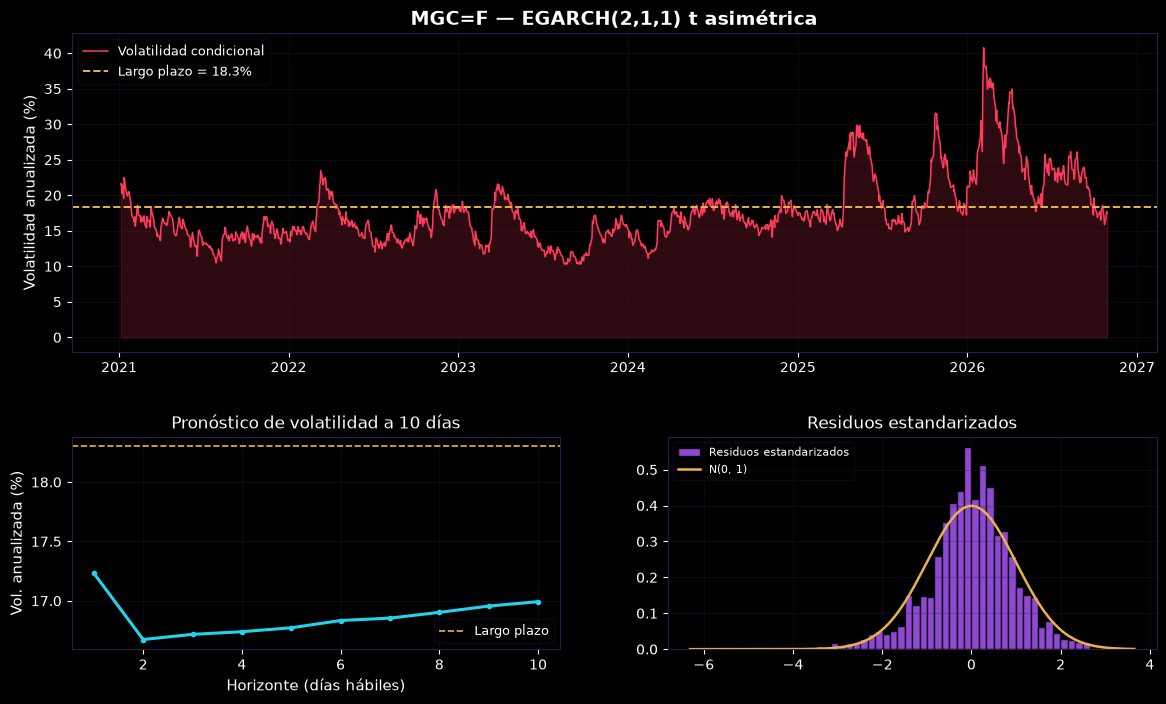

Volatilidad actual:          17.50%
Pronóstico para mañana:      17.23%
Pronóstico a 10 días:        16.99%
Nivel de largo plazo:        18.30%


In [20]:
g.volatilidad(v, garch, PRINCIPAL, guardar='08_volatilidad')

print(f"Volatilidad actual:          {v['vol_cond'].iloc[-1]:.2f}%")
print(f"Pronóstico para mañana:      {v['vol_pron'][0]:.2f}%")
print(f"Pronóstico a {HORIZONTE_VOL} días:        {v['vol_pron'][-1]:.2f}%")
print(f"Nivel de largo plazo:        {v['vol_lp']:.2f}%")

## Resumen

In [21]:
pd.Series({
    f'Volatilidad anual {TICKER}': f"{s['vol_a']:.1%}",
    f'VaR 95% diario {TICKER}': f"{s['var']:.2%}",
    f'Grados de libertad t {TICKER}': f"{ajuste['t'][0]:.1f}",
    f'Orden ARIMA {PRINCIPAL}': str(orden),
    'U de Theil a 1 paso': f"{tabla_eval['U de Theil'].iloc[0]:.3f}",
    'Modelo de volatilidad': config['nombre'],
    'Volatilidad actual': f"{v['vol_cond'].iloc[-1]:.1f}%",
    f'Volatilidad a {HORIZONTE_VOL} días': f"{v['vol_pron'][-1]:.1f}%",
    'Vida media de un shock': f"{v['vida_media']:.1f} días",
}, name='Valor').to_frame()

,Valor
Volatilidad anual MGC=F,18.5%
VaR 95% diario MGC=F,-1.85%
Grados de libertad t MGC=F,3.6
Orden ARIMA MGC=F,"(3, 1, 3)"
U de Theil a 1 paso,0.985
Modelo de volatilidad,"EGARCH(2,1,1) t asimétrica"
Volatilidad actual,17.5%
Volatilidad a 10 días,17.0%
Vida media de un shock,39.9 días


**Conclusiones**

- Los retornos no son normales: colas pesadas y más días extremos de los que predice la normal. Para medir riesgo conviene el VaR histórico o con t.
- El precio no es predecible con ARIMA: frente al paseo aleatorio la U de Theil queda alrededor de 1.
- La volatilidad sí es predecible: hay efecto ARCH claro y los shocks tardan días en disiparse. Es la parte del análisis que sirve en la práctica (tamaño de posición, stops, VaR condicional).

**Limitaciones**

- Futuros continuos de Yahoo sin ajuste por roll.
- No hay costos de transacción ni re-estimación de los modelos en el test (walk-forward).
- Es un ejercicio de análisis, no una recomendación de inversión.